He Normal uses the sqrt(2/ fan_in )  

so weights will be random * sqrt( 2 / fan_in )

we also have the Xavier uniform and He uniform . And default is glorat/xavier uniform  in keras 

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv('../../data/ushape.csv')

In [21]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


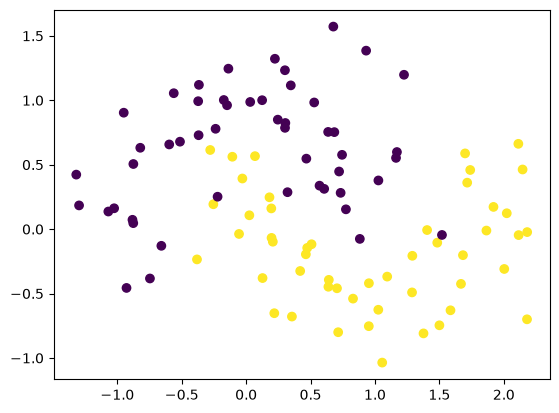

In [22]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [23]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [24]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [25]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2,kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(10,activation='relu',kernel_initializer='he_normal'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/home/foolmann/miniconda3/envs/ml312/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 371 (1.45 KB)

 Trainable params: 371 (1.45 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.get_weights()

[array([[-0.41439378,  1.0276889 , -0.04472236, -1.8325853 , -1.8733076 ,
         -0.68167126, -1.5369741 ,  1.3970693 ,  0.25310683, -0.9751184 ],
        [-1.2135906 , -0.7260834 ,  1.1000713 ,  0.9970749 ,  1.1065772 ,
          0.16100124, -0.6093829 , -0.08055624,  0.48435283, -0.82403207]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.28006592,  0.17654085,  0.08701357,  0.6146518 , -0.42014134,
         -0.20134369,  0.02977105,  0.7901861 , -0.11491192,  0.8944846 ],
        [ 0.66377026,  0.04778711,  0.986917  , -0.07231702,  0.44780257,
         -0.32452434,  0.39328703, -0.3875477 ,  0.29549742, -0.6364284 ],
        [-0.37149066,  0.37866053, -0.18213163,  0.28642774,  0.39333576,
          0.56560576,  0.34947953,  0.22576977, -0.6506068 , -0.2444548 ],
        [-0.40429538,  0.23540474, -0.30565995,  0.4826012 , -0.13840935,
         -0.06149986,  0.2905277 ,  0.8361982 , -0.2742554 ,  0.8400692 ],
        [ 0.22004

In [27]:
initial_weights = model.get_weights()

Using sqrt of ( 2 / fan_in) for the he normal but we used the keras params so not needed here 

In [28]:
# initial_weights[0] = np.random.randn(2,10)*np.sqrt(1/2)
# initial_weights[1] = np.zeros(model.get_weights()[1].shape)
# initial_weights[2] = np.random.randn(10,10)*np.sqrt(1/10)
# initial_weights[3] = np.zeros(model.get_weights()[3].shape)
# initial_weights[4] = np.random.randn(10,10)*np.sqrt(1/10)
# initial_weights[5] = np.zeros(model.get_weights()[5].shape)
# initial_weights[6] = np.random.randn(10,10)*np.sqrt(1/10)
# initial_weights[7] = np.zeros(model.get_weights()[7].shape)
# initial_weights[8] = np.random.randn(10,1)*np.sqrt(1/10)
# initial_weights[9] = np.zeros(model.get_weights()[9].shape)

In [29]:
# model.set_weights(initial_weights)

In [30]:
# model.get_weights()

In [31]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [32]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100


I0000 00:00:1795448663.408698   14784 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_75650__.11


1/3 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.4688 - loss: 0.6995

I0000 00:00:1795448664.030524   14783 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_75650__.11


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 546ms/step - accuracy: 0.5750 - loss: 0.6253 - val_accuracy: 0.7000 - val_loss: 0.5580
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6750 - loss: 0.5922 - val_accuracy: 0.8500 - val_loss: 0.5254
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7250 - loss: 0.5668 - val_accuracy: 0.8500 - val_loss: 0.4957
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7250 - loss: 0.5422 - val_accuracy: 0.8500 - val_loss: 0.4705
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7375 - loss: 0.5179 - val_accuracy: 0.8500 - val_loss: 0.4502
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7375 - loss: 0.5025 - val_accuracy: 0.8500 - val_loss: 0.4314
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7500 - loss: 0.4859 - val_accuracy: 0.8500 - val_loss: 0.4145
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7500 - loss: 0.4713 - val_accuracy: 0.8500 - val_loss: 0.4003
Epo

In [33]:
model.get_weights()

[array([[-0.22095811,  1.0220253 ,  0.0905316 , -1.7458044 , -1.9908924 ,
         -0.6847946 , -1.60842   ,  1.369747  ,  0.28357062, -0.9806063 ],
        [-1.240268  , -0.8904044 ,  1.2309021 ,  1.0353258 ,  1.1055562 ,
          0.12721966, -0.53628916, -0.09918962,  0.58184415, -0.67502356]],
       dtype=float32),
 array([ 0.03601654, -0.02520259,  0.12222844, -0.08073171, -0.03810919,
        -0.12019282, -0.01130993, -0.04187765,  0.06399105, -0.07984598],
       dtype=float32),
 array([[ 0.5194385 ,  0.02082782,  0.30349496,  0.48600036, -0.5673457 ,
         -0.03879902,  0.06773429,  0.7942008 ,  0.0484201 ,  0.79718035],
        [ 0.80589813,  0.03316664,  1.0352571 , -0.1381907 ,  0.30819398,
         -0.31108183,  0.3447475 , -0.51172584,  0.41336837, -0.7314084 ],
        [-0.17984009,  0.4355059 , -0.3251406 ,  0.3987554 ,  0.41113654,
          0.59788543,  0.47774947,  0.30694306, -0.45333692, -0.23537235],
        [-0.4803496 ,  0.2008193 , -0.33554563,  0.5351315 , 

<Axes: >

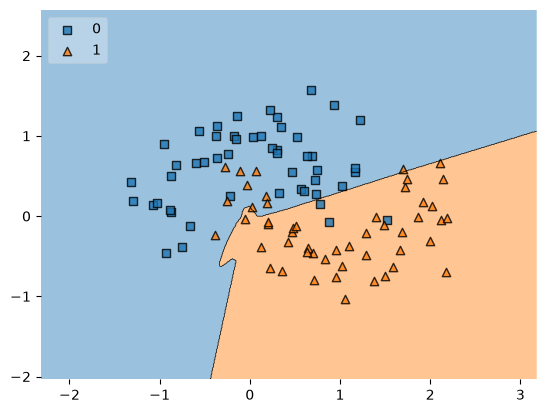

In [34]:
# from mlxtend.plotting import plot_decision_regions
# plot_decision_regions(X,y.astype('int'), clf=model, legend=2)
import numpy as np
from mlxtend.plotting import plot_decision_regions

class KerasClassifier:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        predictions = self.model.predict(X, verbose=0)
        return (predictions.ravel() >= 0.5).astype(int)


# Convert labels to integers
y = y.astype(int)

# Wrap the model
clf = KerasClassifier(model)

# Plot decision regions
plot_decision_regions(X, y, clf=clf, legend=2)

In [35]:
(np.random.randn(10,10)*0.01).min()

np.float64(-0.025153794234140783)

In [36]:
(np.random.randn(10,10)*0.01).max()

np.float64(0.02337353402887054)